# IE7615 – Discriminative Project, Milestone 3
## Multi-object detection with YOLOv8

Aditi Kulkarni · Sakshi Pawar · Aditya Sai Kumar Kusetti · Hemanth Mareedu

In Milestone 1 we classified single-object images (73 classes, best model ResNet50 at ~90% val accuracy). Here the goal is detection, plus a live demo on both single-object and multi-object images: given an image with several objects, predict the Object ID and bounding box of each one.

Since the shared dataset only has single-object photos, we build multi-object images ourselves by tiling the photos into grids (2x2, 3x3 and a few 2x3/3x2), which also gives us the box labels for free. We also include single-photo (1x1) images so the same model can identify one object on its own, which the live demo asks for. Then we fine-tune a pretrained YOLOv8 on those images.

Runtime: Colab, T4 GPU.

### Setup

In [1]:
!nvidia-smi
!pip install -q ultralytics

Thu Oct 15 00:30:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Data

The final merged dataset is added to Drive as a shortcut. We copy it to the local disk first because reading thousands of small files directly from Drive is slow.

In [4]:
import os, glob, shutil, subprocess

DRIVE_DATASET = "/content/drive/MyDrive/IE7615 Deep Learning for AI"   # Drive shortcut to the merged dataset
LOCAL = "/content/data"
os.makedirs(LOCAL, exist_ok=True)

# either copy from Drive, or unzip a zip uploaded to /content
if os.path.exists(DRIVE_DATASET):
    subprocess.run(["cp", "-rL", DRIVE_DATASET, LOCAL], check=True)   # -L copies the real files, not the Drive shortcut
for z in glob.glob("/content/*.zip"):
    subprocess.run(["unzip", "-q", "-o", z, "-d", LOCAL], check=True)

# find the folder that holds the images_OBJxxx folders
SRC, n = None, 0
for d, subs, _ in os.walk(LOCAL):
    k = sum(s.startswith("images_") for s in subs)
    if k > n:
        SRC, n = d, k
print(SRC, "->", n, "class folders")

/content/data/IE7615 Deep Learning for AI -> 73 class folders


### Building the multi-object dataset

- Every photo is already 224x224, so each one fills one grid cell. The YOLO label for an object is just its cell (or a slightly smaller box if we shrink the tile).
- Layout mix: 35% 2x2, 35% 3x3, 15% single photo (1x1), 7.5% 2x3, 7.5% 3x2. Demo images will mostly be 2x2/3x3, but the demo also includes single-object images, and we didn't want the model to only learn one fixed pattern.
- About a quarter of the grid images leave 1–2 cells empty so the number of objects isn't always the same (never for 1x1).
- Background-only photos from Milestone 1 are dropped.
- Train/val/test split (70/15/15) is done on the original photos **before** making grids. Otherwise the same photo could show up in both a training grid and a test grid and inflate the test score.
- For training images only: random horizontal flip, brightness jitter, and sometimes shrinking a tile and placing it at a random spot inside its cell.

2000 images total. The requirement is 100 per student (400 minimum for our team of four); we generated more so each of the 73 classes appears often enough to learn from.

In [8]:
import random, re
from pathlib import Path
from PIL import Image, ImageEnhance

TILE = 224
N_IMAGES = 2000
SEED = 42
OUT = Path("/content/dataset")

layouts = [(1, 1), (2, 2), (3, 3), (2, 3), (3, 2)]
layout_w = [0.15, 0.35, 0.35, 0.075, 0.075]
split_frac = {"train": 0.70, "val": 0.15, "test": 0.15}
is_bg = re.compile(r"(?:^|[_\-\s])(bg|background)(?:[_\-\s\d.]|$)", re.I)

# collect images per class
folders = sorted(p for p in Path(SRC).iterdir() if p.is_dir() and p.name.startswith("images_"))
classes, files = [], []
n_bg = 0
for folder in folders:
    imgs = []
    for f in sorted(folder.iterdir()):
        if f.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue
        if is_bg.search(f.stem):
            n_bg += 1
            continue
        imgs.append(f)
    if imgs:
        classes.append(folder.name.replace("images_", "", 1))
        files.append(imgs)
print(len(classes), "classes |", sum(len(x) for x in files), "images |", n_bg, "background images removed")

# split per class on the single photos
rng = random.Random(SEED)
pools = {s: [] for s in split_frac}
for imgs in files:
    imgs = imgs[:]
    rng.shuffle(imgs)
    a = int(len(imgs) * 0.70)
    b = a + int(len(imgs) * 0.15)
    pools["train"].append(imgs[:a])
    pools["val"].append(imgs[a:b])
    pools["test"].append(imgs[b:])

73 classes | 6958 images | 385 background images removed


In [9]:
def get_tile(path, augment):
    img = Image.open(path).convert("RGB")
    if img.size != (TILE, TILE):
        img = img.resize((TILE, TILE))
    if augment:
        if rng.random() < 0.5:
            img = img.transpose(Image.FLIP_LEFT_RIGHT)
        if rng.random() < 0.5:
            img = ImageEnhance.Brightness(img).enhance(rng.uniform(0.75, 1.25))
    return img


def make_grid(pool, augment=False, layout=None, allow_empty=True):
    rows, cols = layout if layout else rng.choices(layouts, weights=layout_w)[0]
    n_cells = rows * cols
    W, H = cols * TILE, rows * TILE
    canvas = Image.new("RGB", (W, H), (114, 114, 114))

    n_obj = n_cells
    if allow_empty and n_cells >= 4 and rng.random() < 0.25:
        n_obj = max(2, n_cells - rng.randint(1, 2))
    cells = rng.sample(range(n_cells), n_obj)
    cls_ids = rng.sample(range(len(pool)), n_obj)   # different objects in each image

    labels = []
    for cell, cid in zip(cells, cls_ids):
        tile = get_tile(rng.choice(pool[cid]), augment)
        r, c = divmod(cell, cols)
        x, y = c * TILE, r * TILE
        if augment and rng.random() < 0.3:
            s = int(TILE * rng.uniform(0.7, 0.95))
            tile = tile.resize((s, s))
            x += rng.randint(0, TILE - s)
            y += rng.randint(0, TILE - s)
        w, h = tile.size
        canvas.paste(tile, (x, y))
        labels.append(f"{cid} {(x + w/2)/W:.6f} {(y + h/2)/H:.6f} {w/W:.6f} {h/H:.6f}")
    return canvas, labels


if OUT.exists():
    shutil.rmtree(OUT)
for split, frac in split_frac.items():
    (OUT / "images" / split).mkdir(parents=True)
    (OUT / "labels" / split).mkdir(parents=True)
    for i in range(int(N_IMAGES * frac)):
        img, labels = make_grid(pools[split], augment=(split == "train"))
        img.save(OUT / "images" / split / f"{split}_{i:05d}.jpg", quality=95)
        (OUT / "labels" / split / f"{split}_{i:05d}.txt").write_text("\n".join(labels) + "\n")
    print(split, int(N_IMAGES * frac))

with open(OUT / "data.yaml", "w") as f:
    f.write(f"path: {OUT}\ntrain: images/train\nval: images/val\ntest: images/test\n")
    f.write(f"nc: {len(classes)}\nnames:\n")
    for i, c in enumerate(classes):
        f.write(f"  {i}: '{c}'\n")

# one full 2x2 and one full 3x3 example
os.makedirs(OUT / "examples", exist_ok=True)
for lay in [(1, 1), (2, 2), (3, 3)]:
    img, _ = make_grid(pools["train"], layout=lay, allow_empty=False)
    img.save(OUT / "examples" / f"sample_{lay[0]}x{lay[1]}.jpg", quality=95)

train 1400
val 300
test 300


Quick sanity check that the boxes and class names line up (and that no background photos got through).

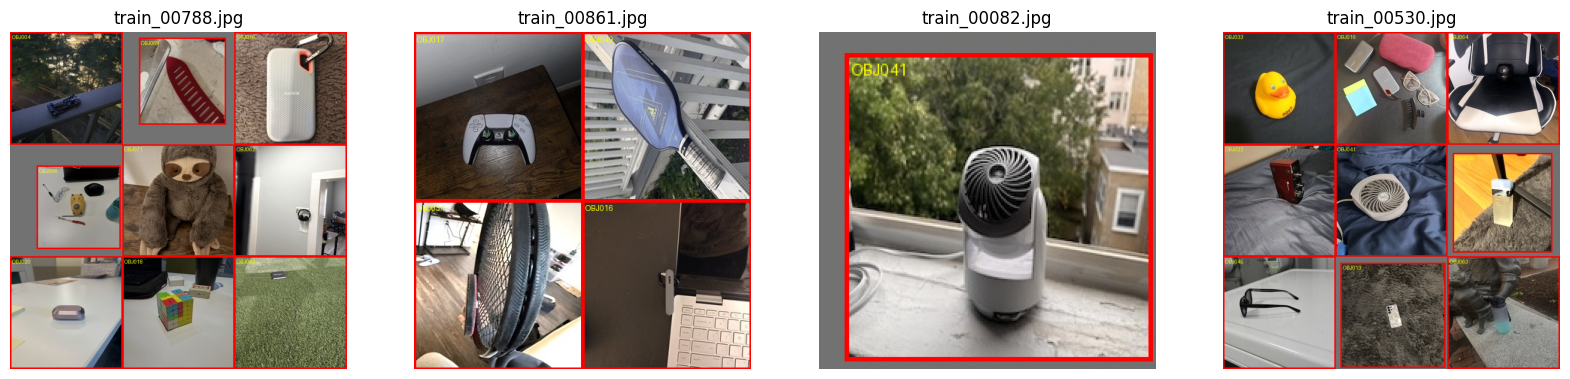

In [10]:
import matplotlib.pyplot as plt
from PIL import ImageDraw

def draw(img_path):
    img = Image.open(img_path).convert("RGB")
    d = ImageDraw.Draw(img)
    W, H = img.size
    lbl = OUT / "labels" / img_path.parent.name / (img_path.stem + ".txt")
    for line in lbl.read_text().strip().split("\n"):
        cid, cx, cy, w, h = line.split()
        cx, cy, w, h = float(cx) * W, float(cy) * H, float(w) * W, float(h) * H
        d.rectangle([cx - w/2, cy - h/2, cx + w/2, cy + h/2], outline="red", width=3)
        d.text((cx - w/2 + 4, cy - h/2 + 4), classes[int(cid)], fill="yellow")
    return img

sample = random.Random(0).sample(sorted((OUT / "images" / "train").glob("*.jpg")), 4)
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
for a, p in zip(ax, sample):
    a.imshow(draw(p)); a.set_title(p.name); a.axis("off")
plt.show()

### Training

YOLOv8s pretrained on COCO, fine-tuned on our grids.

- `imgsz=672` because a 3x3 grid is exactly 672x672, so the tiles don't get downscaled.
- Mosaic augmentation turned down to 0.5. Our images are already multi-object and full mosaic cuts tiles up a lot.
- Early stopping with patience 15.

In [11]:
import time
from ultralytics import YOLO

t0 = time.time()
model = YOLO("yolov8s.pt")
model.train(
    data=str(OUT / "data.yaml"),
    epochs=60,
    imgsz=672,
    batch=16,
    patience=15,
    mosaic=0.5,
    close_mosaic=10,
    fliplr=0.5,
    seed=SEED,
    project="/content/runs",
    name="yolov8s_v2",
    exist_ok=True,
)
train_time = (time.time() - t0) / 60
run_dir = Path(model.trainer.save_dir)
print(f"training took {train_time:.1f} min")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, free

### Evaluation on the test split

In [13]:
best = YOLO(str(run_dir / "weights" / "best.pt"))
metrics = best.val(data=str(OUT / "data.yaml"), split="test", imgsz=672,
                   project="/content/runs", name="test", exist_ok=True)
test_dir = Path(metrics.save_dir)

print(f"mAP50     {metrics.box.map50:.4f}")
print(f"mAP50-95  {metrics.box.map:.4f}")
print(f"precision {metrics.box.mp:.4f}")
print(f"recall    {metrics.box.mr:.4f}")

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1232.6±460.9 MB/s, size: 100.8 KB)
val: Scanning /content/dataset/labels/test.cache... 300 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 59.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 2.9it/s 6.6s
                   all        300       1589      0.981      0.942      0.972      0.972
                OBJ001         24         24      0.991          1      0.995      0.995
                OBJ002         22         22      0.993          1      0.995      0.995
                OBJ003         28         28          1      0.878      0.988      0.988
                OBJ004         26         26      0.921          1      0.991      0.991
                OBJ005         25         25  

In [14]:
import pandas as pd

per_class = pd.DataFrame({
    "object_id": [best.names[int(i)] for i in metrics.box.ap_class_index],
    "AP50": metrics.box.ap50,
    "AP50-95": metrics.box.ap,
}).sort_values("AP50-95")
per_class.to_csv("/content/runs/per_class_ap.csv", index=False)

print("lowest:")
print(per_class.head(5).to_string(index=False))
print("\nhighest:")
print(per_class.tail(5).to_string(index=False))

lowest:
object_id     AP50  AP50-95
   OBJ034 0.680197 0.680197
   OBJ057 0.713788 0.713788
   OBJ013 0.789951 0.789951
   OBJ045 0.865000 0.865000
   OBJ016 0.870000 0.870000

highest:
object_id  AP50  AP50-95
   OBJ067 0.995    0.995
   OBJ069 0.995    0.995
   OBJ071 0.995    0.995
   OBJ072 0.995    0.995
   OBJ073 0.995    0.995


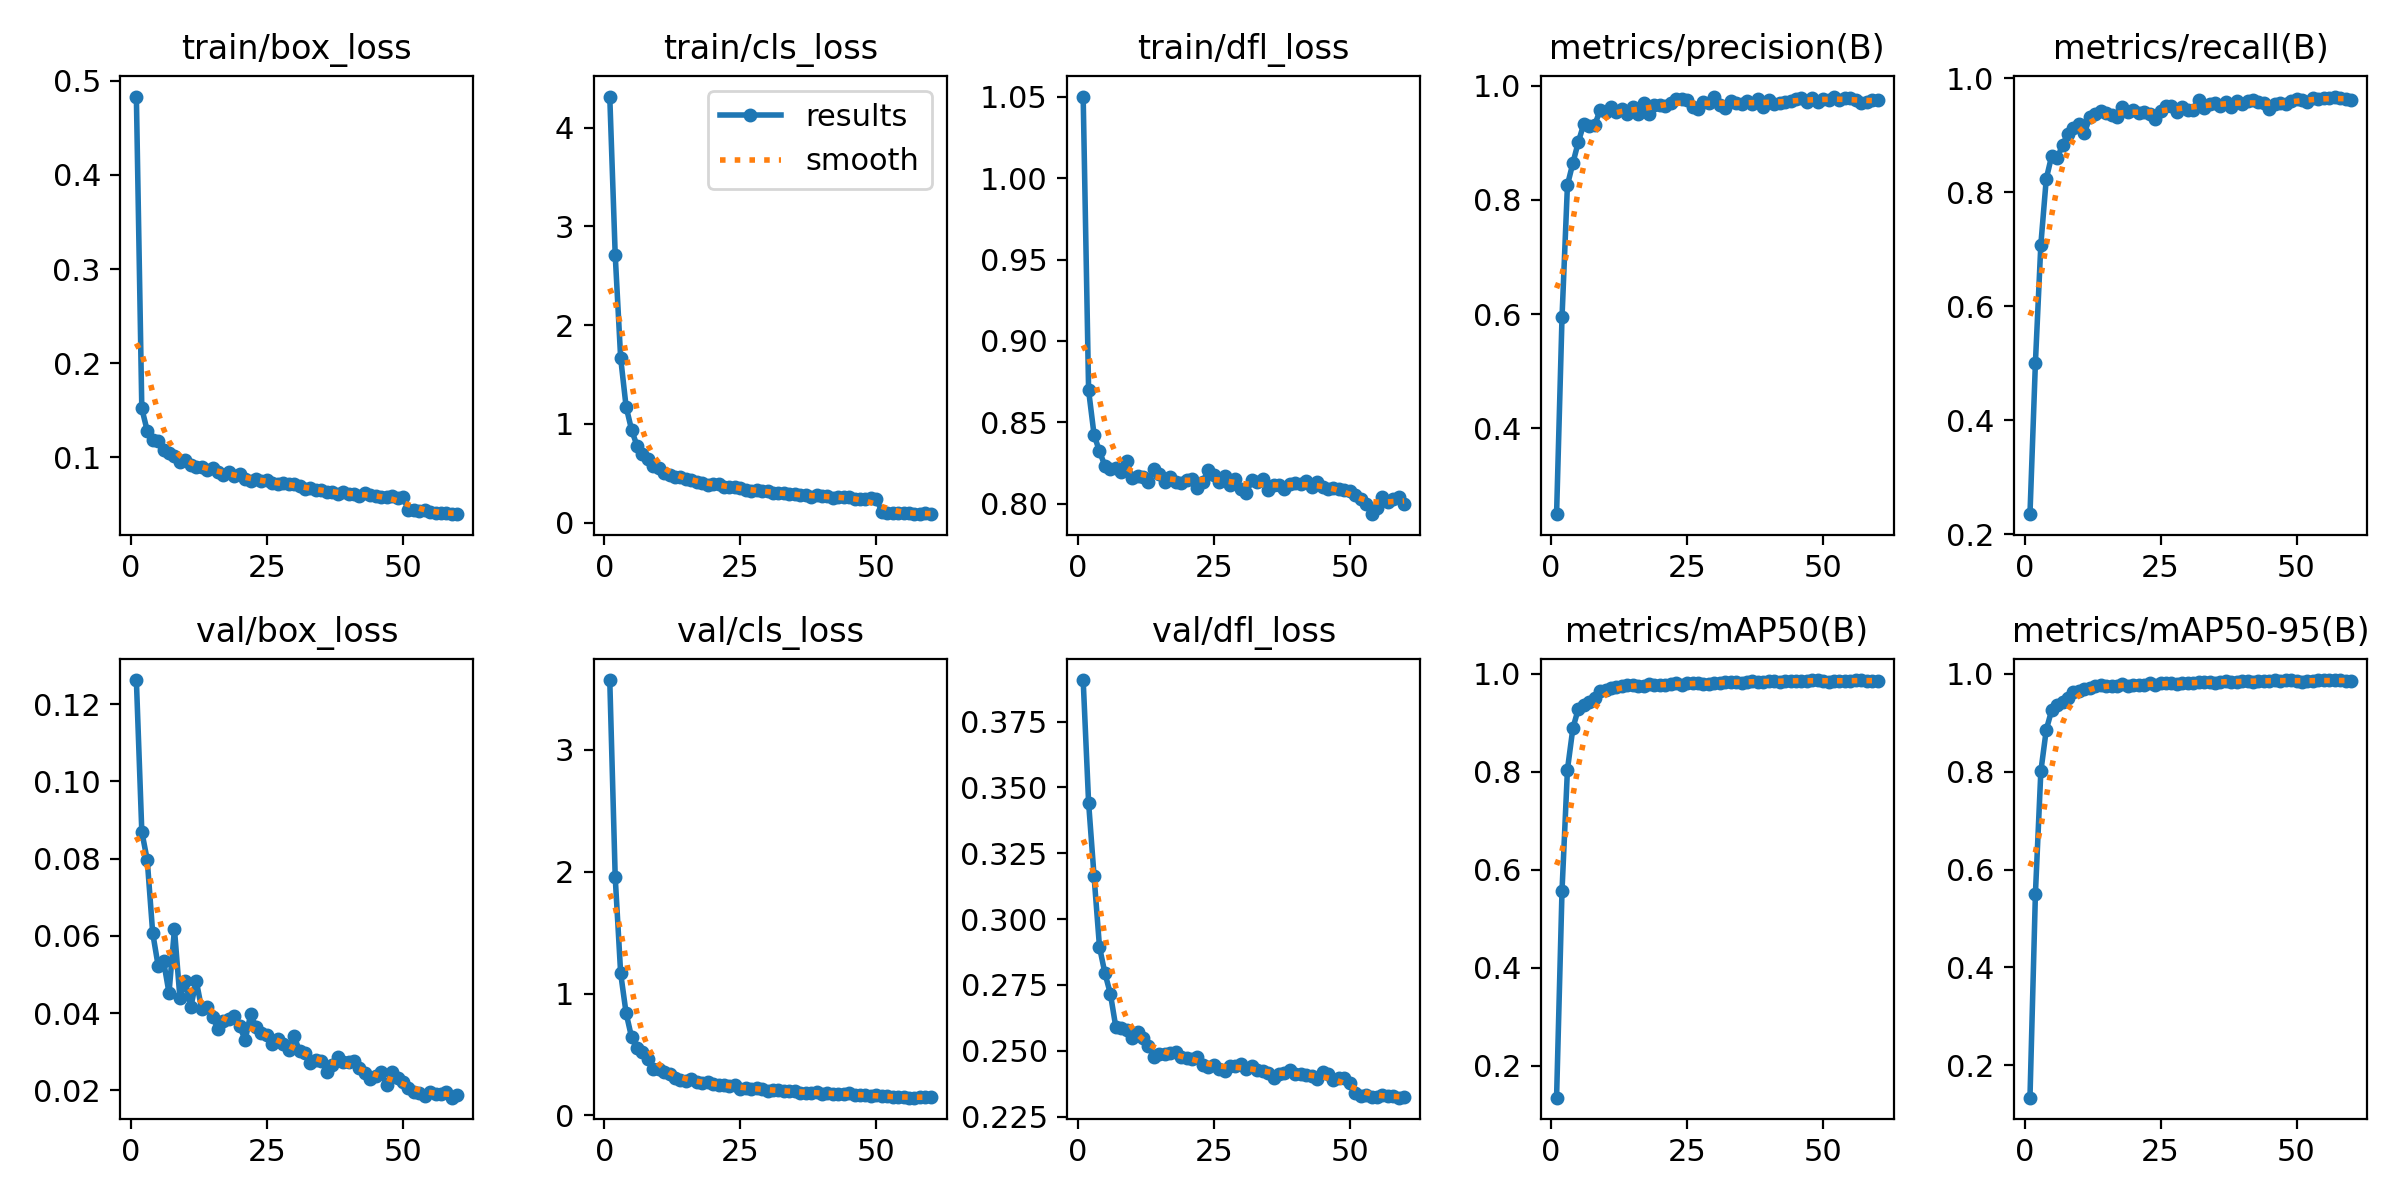

BoxPR_curve.png


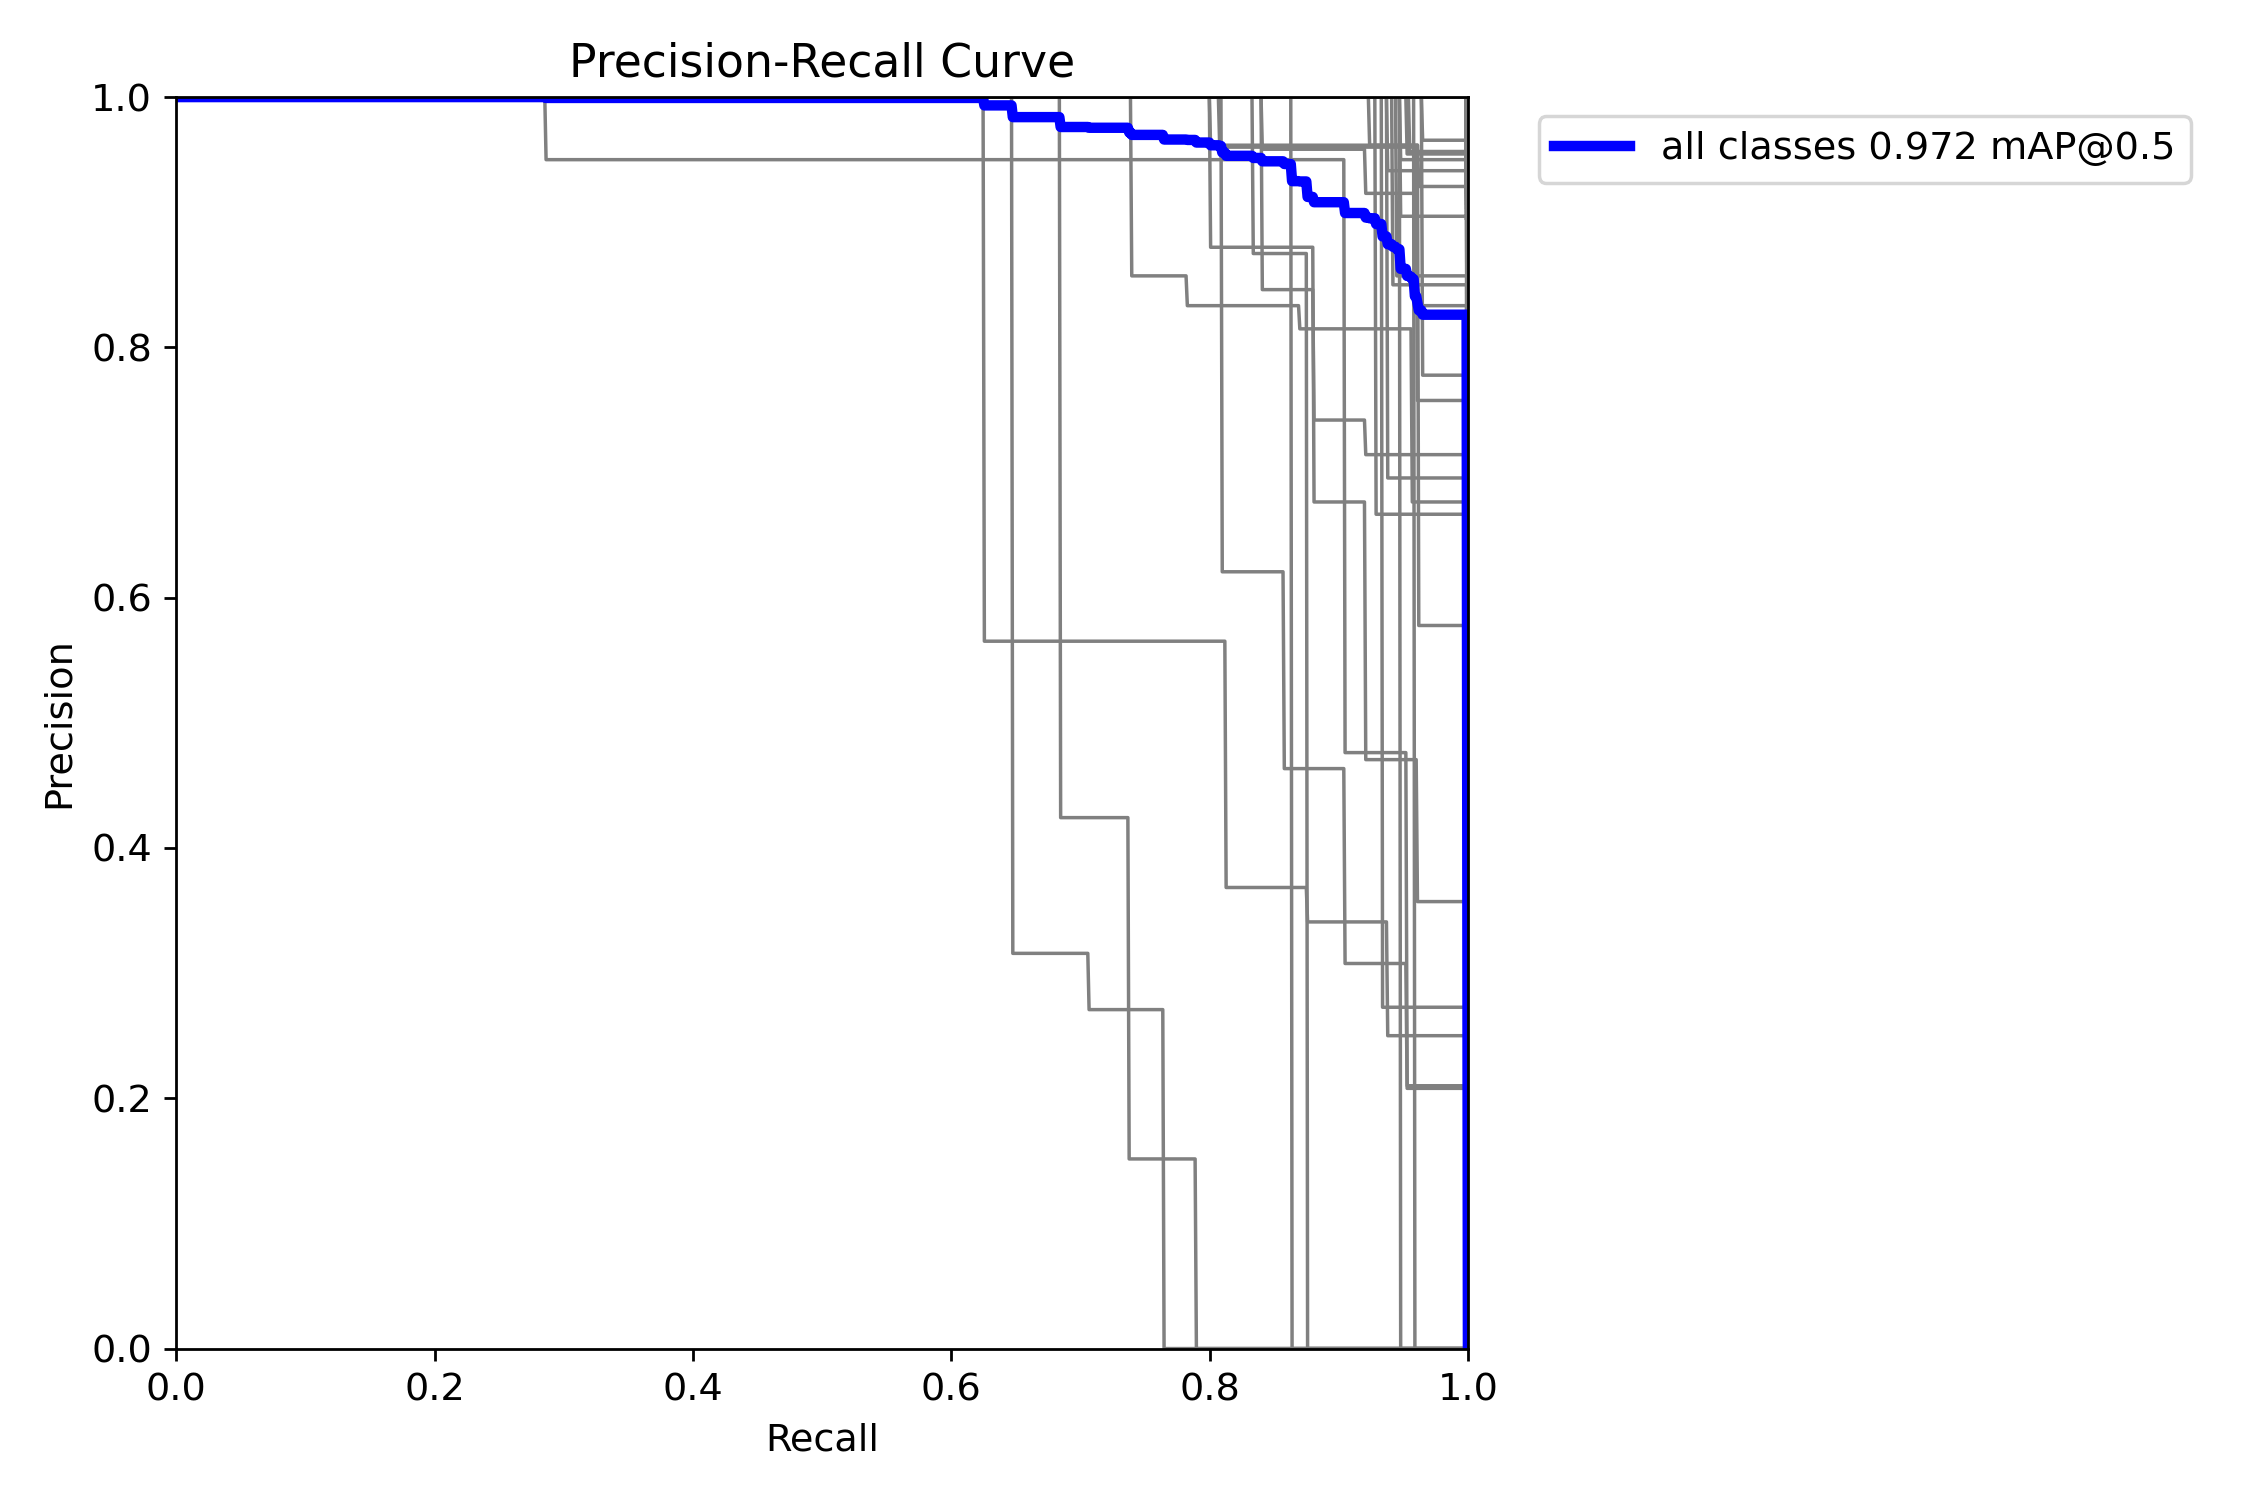

confusion_matrix_normalized.png


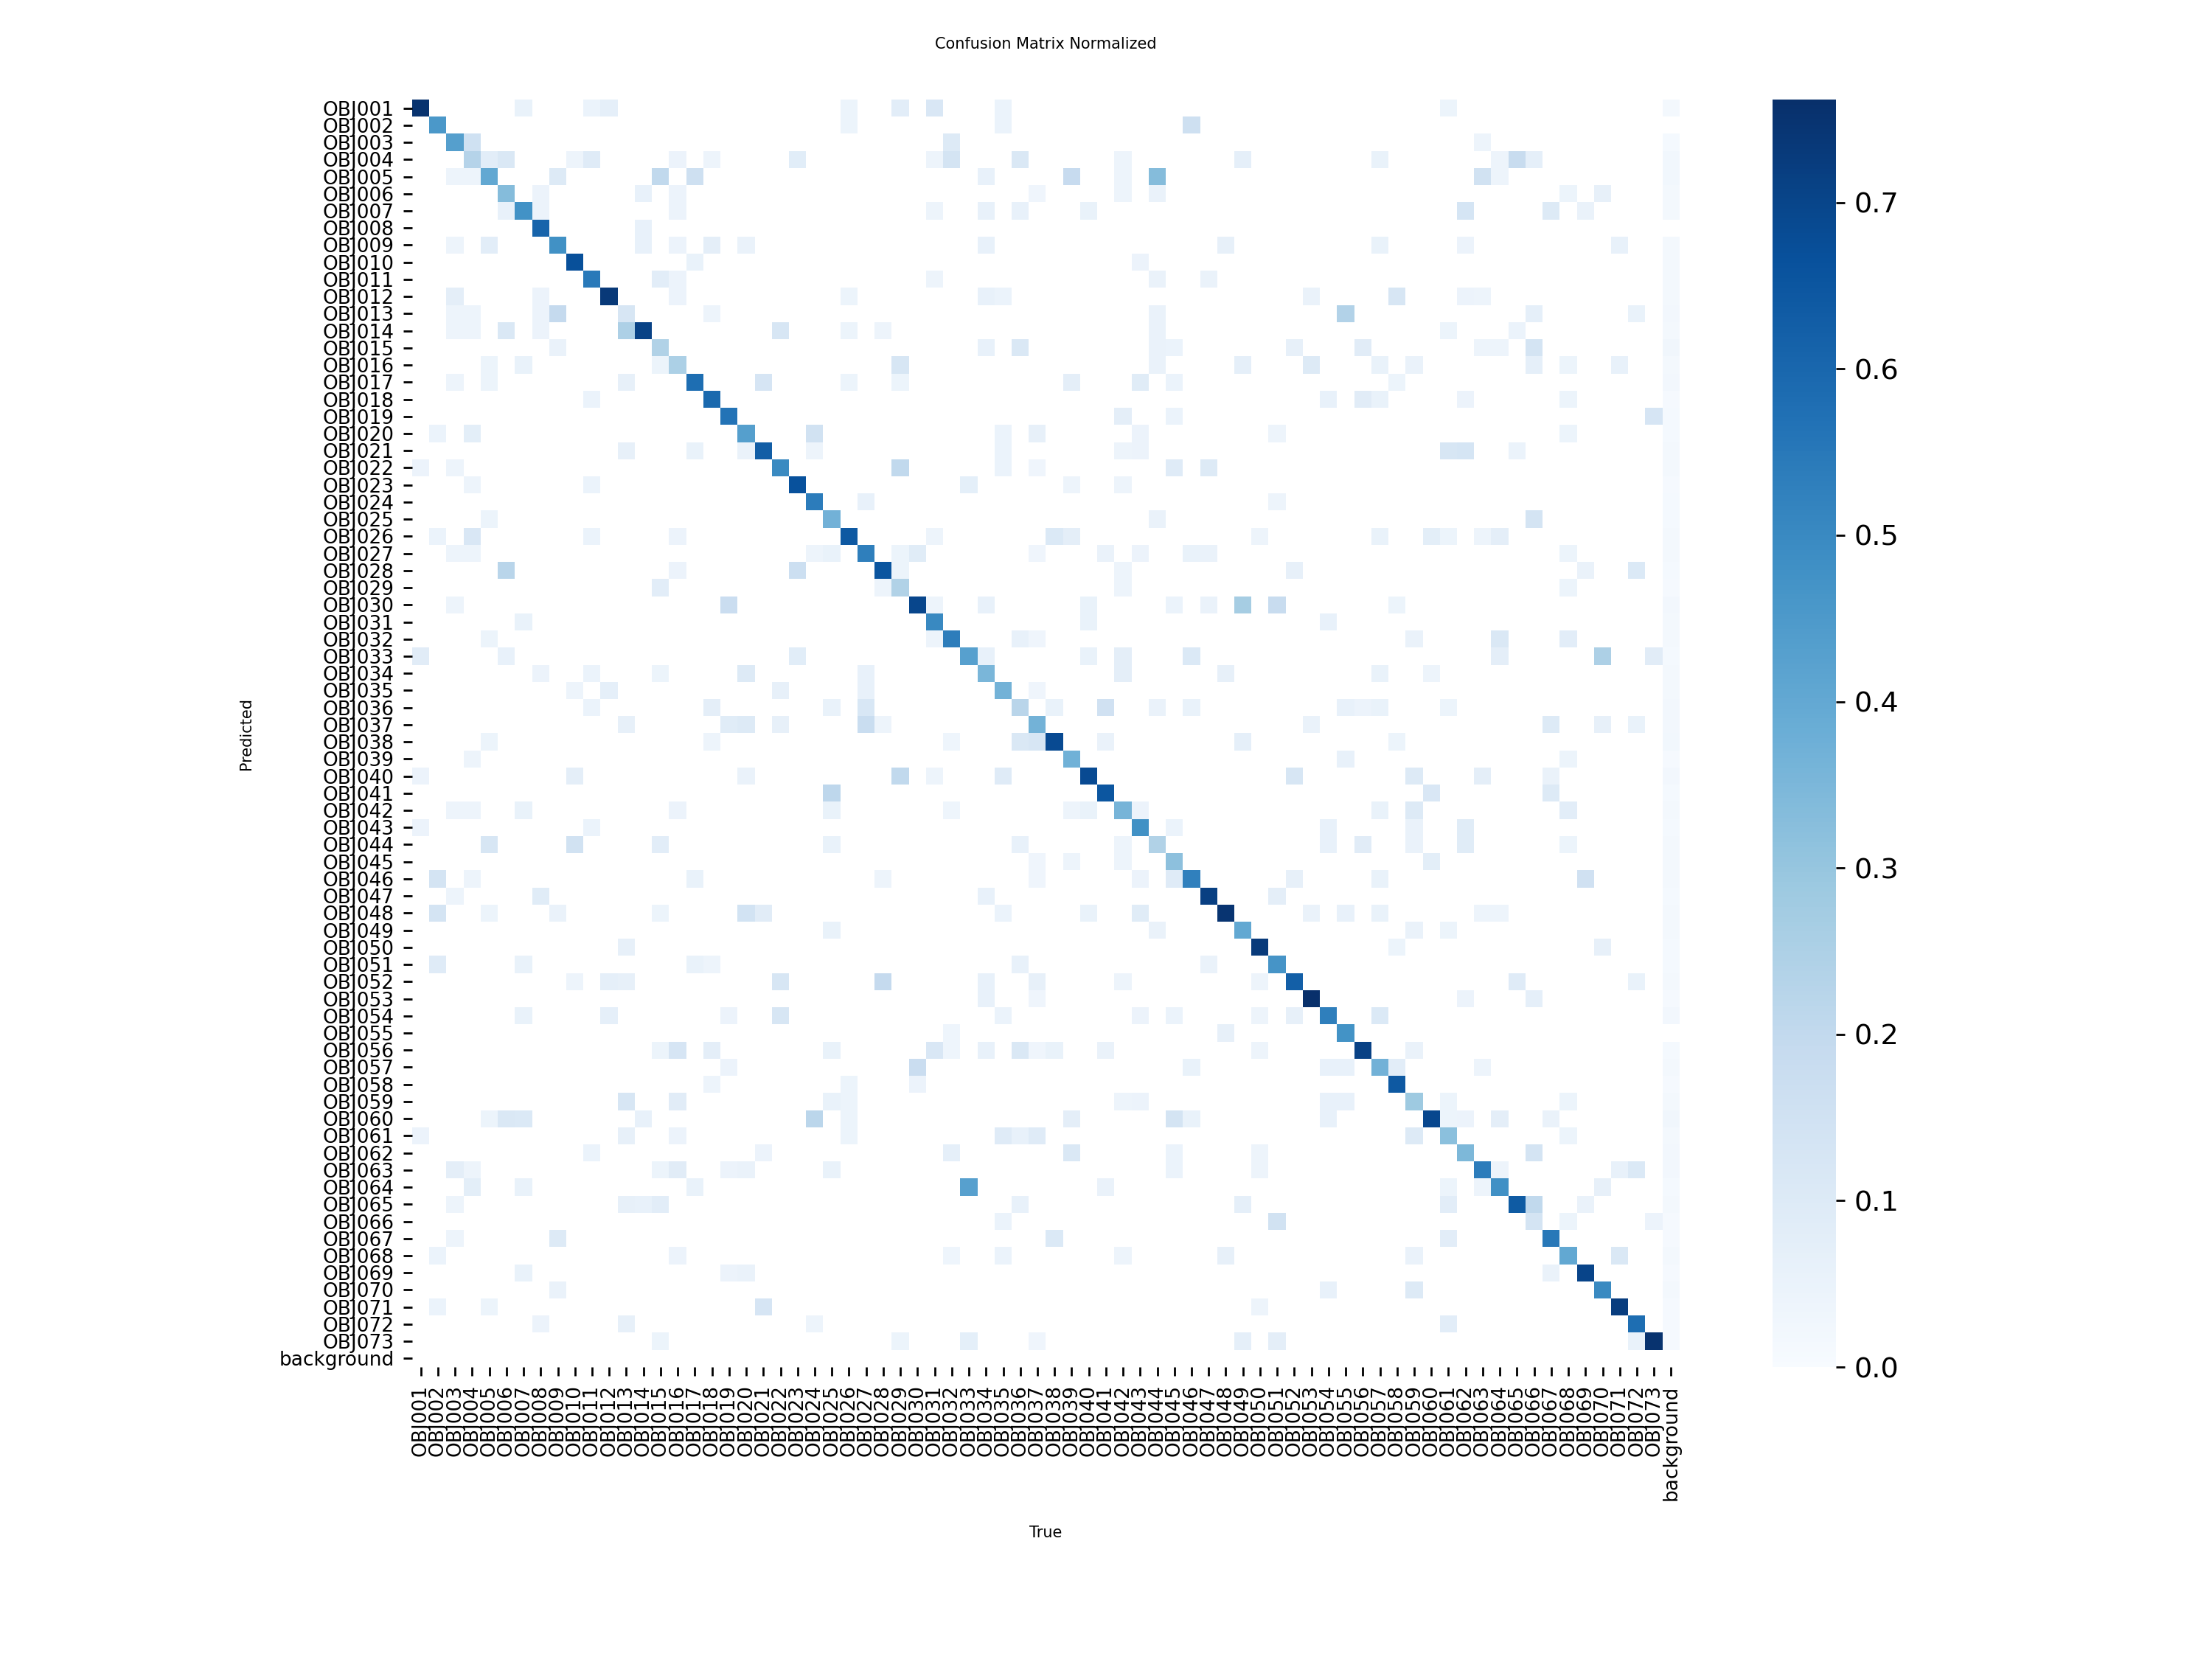

In [15]:
from IPython.display import Image as show_img, display

display(show_img(filename=str(run_dir / "results.png"), width=900))
for p in sorted(test_dir.glob("*PR_curve.png")) + sorted(test_dir.glob("confusion_matrix_normalized.png")):
    print(p.name)
    display(show_img(filename=str(p), width=800))

### Sample predictions


0: 672x672 1 OBJ003, 1 OBJ018, 1 OBJ031, 1 OBJ038, 1 OBJ044, 13.1ms
1: 672x672 1 OBJ021, 1 OBJ029, 1 OBJ050, 1 OBJ073, 13.1ms
2: 672x672 1 OBJ004, 1 OBJ018, 1 OBJ073, 13.1ms
3: 672x672 1 OBJ002, 1 OBJ018, 1 OBJ055, 1 OBJ067, 13.1ms
4: 672x672 1 OBJ003, 1 OBJ033, 1 OBJ067, 1 OBJ073, 13.1ms
5: 672x672 1 OBJ005, 1 OBJ010, 1 OBJ029, 1 OBJ045, 1 OBJ054, 1 OBJ058, 1 OBJ066, 13.1ms
6: 672x672 1 OBJ008, 1 OBJ037, 1 OBJ038, 1 OBJ040, 1 OBJ043, 1 OBJ044, 1 OBJ052, 1 OBJ057, 1 OBJ059, 13.1ms
7: 672x672 1 OBJ003, 1 OBJ012, 1 OBJ040, 1 OBJ072, 13.1ms
8: 672x672 1 OBJ003, 13.1ms
9: 672x672 1 OBJ019, 1 OBJ026, 1 OBJ030, 1 OBJ038, 1 OBJ047, 1 OBJ051, 1 OBJ054, 1 OBJ063, 1 OBJ065, 13.1ms
10: 672x672 1 OBJ041, 1 OBJ042, 1 OBJ046, 1 OBJ058, 13.1ms
11: 672x672 1 OBJ004, 1 OBJ025, 13.1ms
12: 672x672 1 OBJ002, 1 OBJ016, 1 OBJ018, 1 OBJ019, 1 OBJ020, 1 OBJ024, 1 OBJ030, 1 OBJ031, 1 OBJ058, 13.1ms
13: 672x672 1 OBJ004, 1 OBJ014, 1 OBJ037, 1 OBJ050, 1 OBJ060, 1 OBJ061, 1 OBJ064, 1 OBJ068, 1 OBJ073, 13.1ms
14:

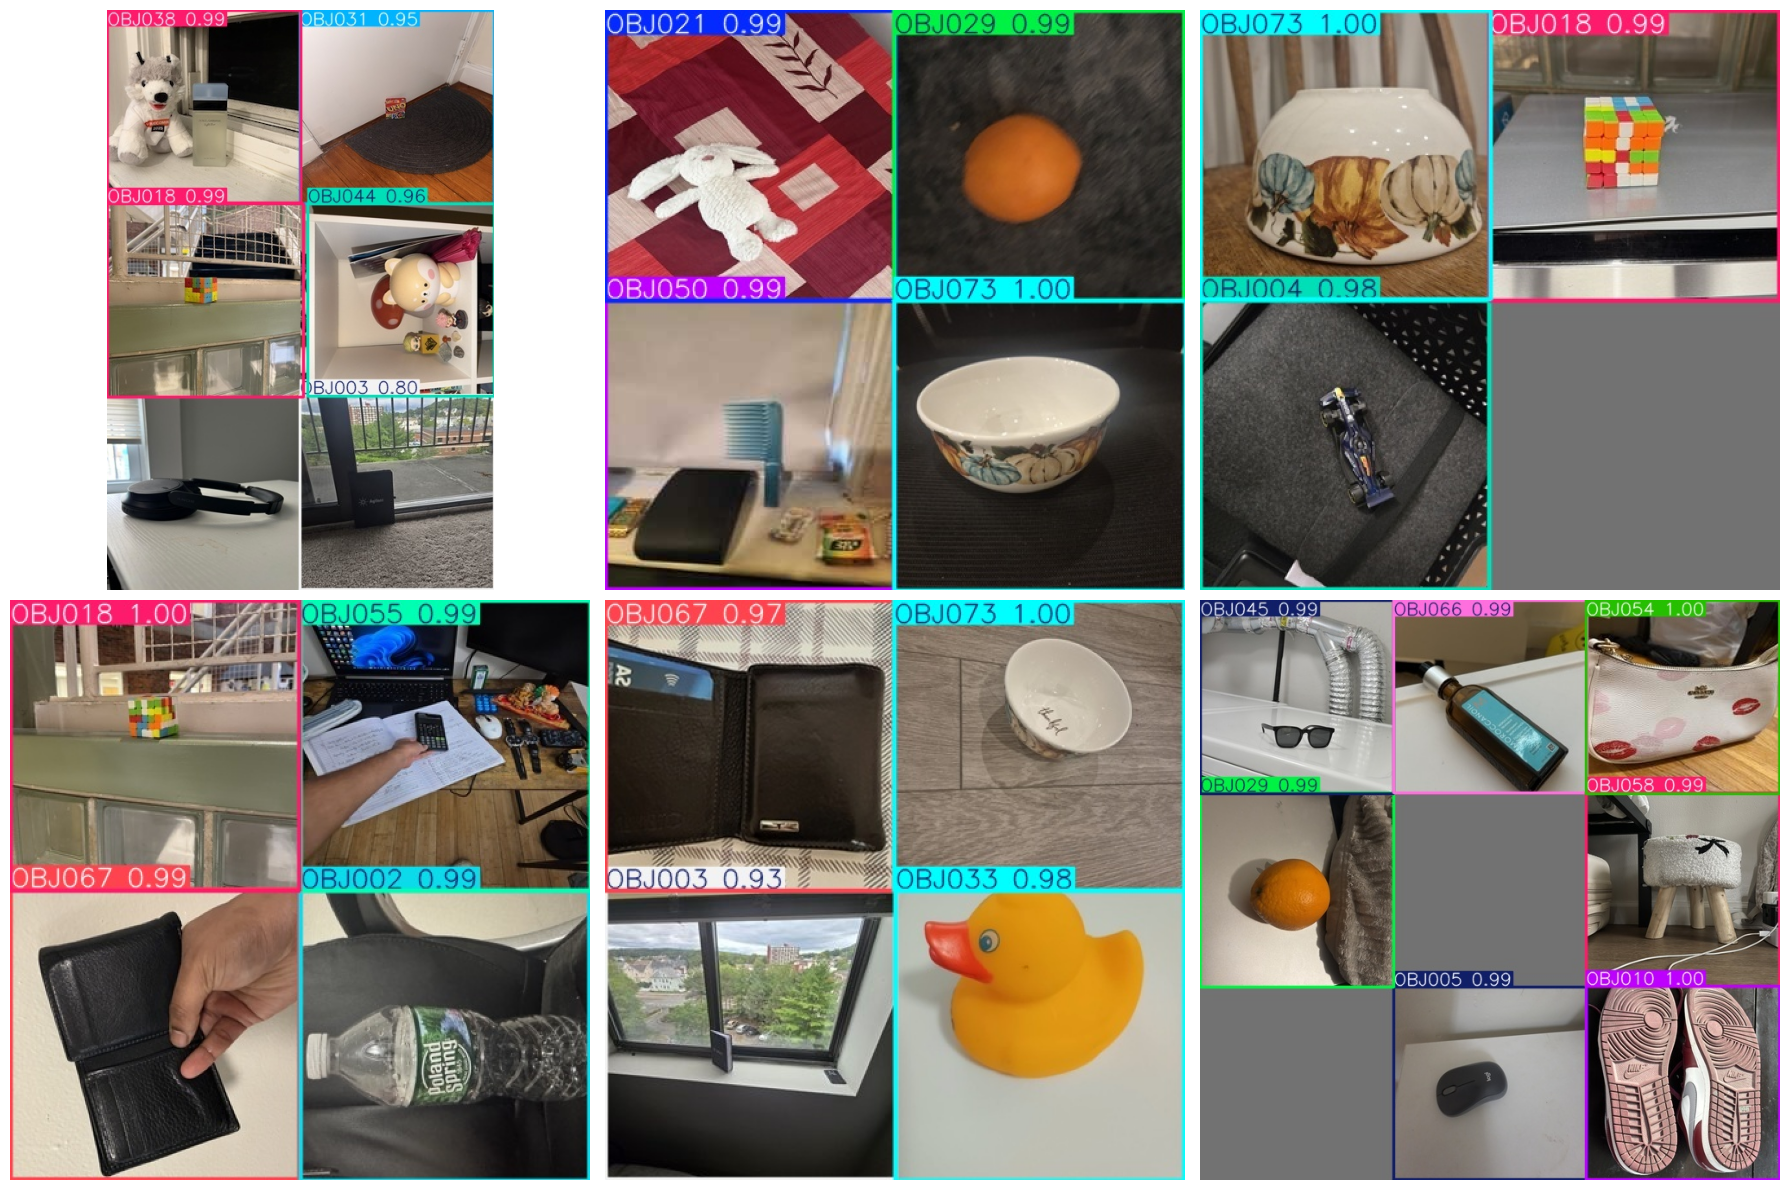

In [16]:
test_imgs = sorted((OUT / "images" / "test").glob("*.jpg"))[:20]
preds = best.predict([str(p) for p in test_imgs], imgsz=672, conf=0.4, agnostic_nms=True, save=True,
                     project="/content/runs", name="predictions", exist_ok=True)
pred_dir = Path(preds[0].save_dir)

fig, ax = plt.subplots(2, 3, figsize=(18, 12))
for a, p in zip(ax.flat, sorted(pred_dir.glob("*.jpg"))[:6]):
    a.imshow(Image.open(p)); a.axis("off")
plt.tight_layout()
plt.show()

### Single-object check

Every held-out test photo (never used in training) is passed in on its own, the way a single-object image would be given in the demo. We take the most confident box and check its class.

In [17]:
correct, total, wrong = 0, 0, []
for cid, imgs in enumerate(pools["test"]):
    for p in imgs:
        r = best.predict(str(p), imgsz=672, conf=0.05, agnostic_nms=True, verbose=False)[0]
        pred = best.names[int(r.boxes.cls[r.boxes.conf.argmax()])] if len(r.boxes) else None
        total += 1
        if pred == classes[cid]:
            correct += 1
        else:
            wrong.append((p.name, classes[cid], pred))
print(f"single-object accuracy: {correct}/{total} = {correct / total:.3f}")
print("some mistakes:", wrong[:10])

single-object accuracy: 910/1101 = 0.827
some mistakes: [('OBJ001_005.jpg', 'OBJ001', 'OBJ049'), ('OBJ001_070.jpg', 'OBJ001', 'OBJ046'), ('OBJ002_059.jpg', 'OBJ002', 'OBJ027'), ('OBJ002_095.jpg', 'OBJ002', 'OBJ065'), ('OBJ002_092.jpg', 'OBJ002', 'OBJ013'), ('OBJ002_028.jpg', 'OBJ002', 'OBJ050'), ('OBJ003_016.jpg', 'OBJ003', 'OBJ042'), ('OBJ003_057.jpg', 'OBJ003', 'OBJ045'), ('OBJ003_070.jpg', 'OBJ003', 'OBJ041'), ('OBJ004_050.jpg', 'OBJ004', 'OBJ033')]


### Single-object input format

Passing a single photo in directly gave 82.7%. The model learned objects mostly at grid-tile scale, so we also tried presenting the photo as one tile of a grid. Results on all 1,101 held-out test photos:

| Input | Accuracy |
|---|---|
| Photo passed in directly | 910 / 1101 = 82.7% |
| Top-left cell of a 2x2-sized gray canvas | 1065 / 1101 = 96.7% |
| Center cell of a 3x3-sized gray canvas | 1064 / 1101 = 96.6% |

We use the 2x2 placement for single-object images in the demo (see `IE7615_Milestone3_Demo.ipynb`).

In [ ]:
def variants(img):
    img = img.convert("RGB").resize((224, 224))
    a = Image.new("RGB", (448, 448), (114, 114, 114)); a.paste(img, (0, 0))
    b = Image.new("RGB", (672, 672), (114, 114, 114)); b.paste(img, (224, 224))
    return {"direct": img, "2x2 corner": a, "3x3 center": b}

scores = {}
for cid, imgs in enumerate(pools["test"]):
    for p in imgs:
        for name, im in variants(Image.open(p)).items():
            r = best.predict(im, imgsz=672, conf=0.05, agnostic_nms=True, verbose=False)[0]
            pred = best.names[int(r.boxes.cls[r.boxes.conf.argmax()])] if len(r.boxes) else None
            s = scores.setdefault(name, [0, 0]); s[1] += 1; s[0] += (pred == classes[cid])
for k, (c, t) in scores.items():
    print(f"{k:12s} {c}/{t} = {c / t:.3f}")

### Predict on a new image

sample_1x1.jpg
  OBJ073  0.91  (0, 0, 224, 224)


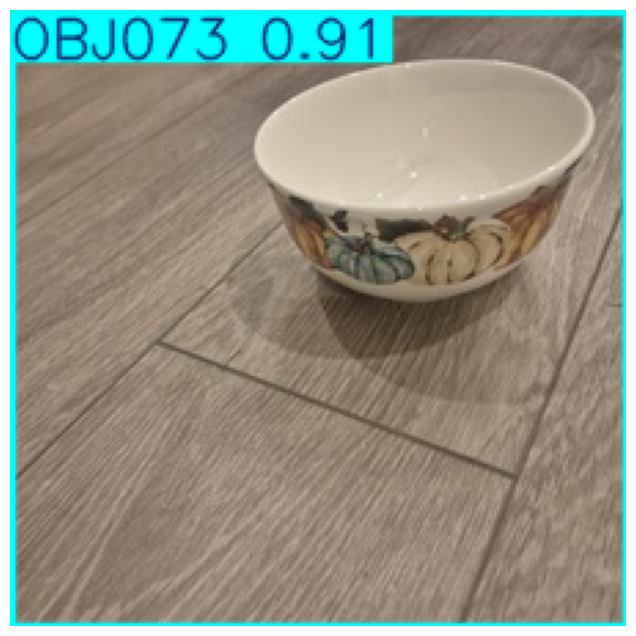

sample_2x2.jpg
  OBJ065  1.00  (224, 223, 447, 447)
  OBJ056  1.00  (0, 0, 224, 223)
  OBJ025  0.99  (223, 0, 447, 224)
  OBJ041  0.99  (0, 224, 223, 447)


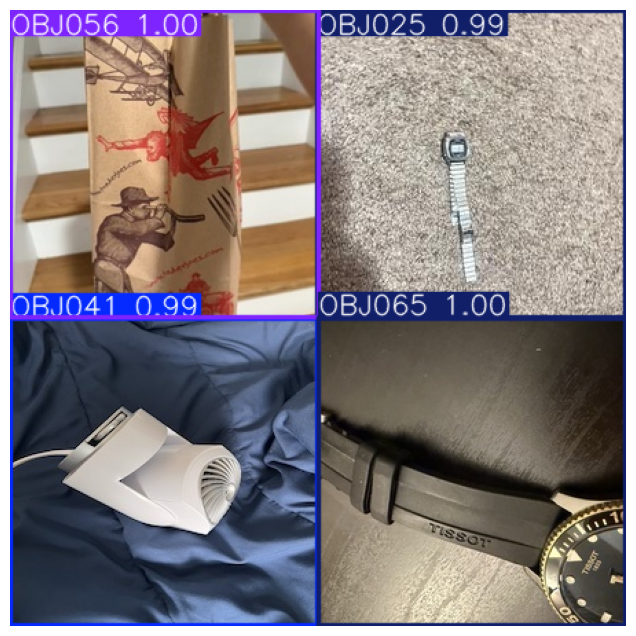

sample_3x3.jpg
  OBJ016  1.00  (448, 224, 672, 448)
  OBJ004  1.00  (0, 447, 223, 672)
  OBJ071  0.99  (0, 223, 224, 447)
  OBJ009  0.99  (223, 0, 448, 224)
  OBJ073  0.99  (447, 447, 672, 672)
  OBJ059  0.99  (223, 447, 447, 672)
  OBJ041  0.99  (448, 0, 672, 224)
  OBJ005  0.99  (223, 224, 448, 447)
  OBJ068  0.98  (0, 0, 223, 224)


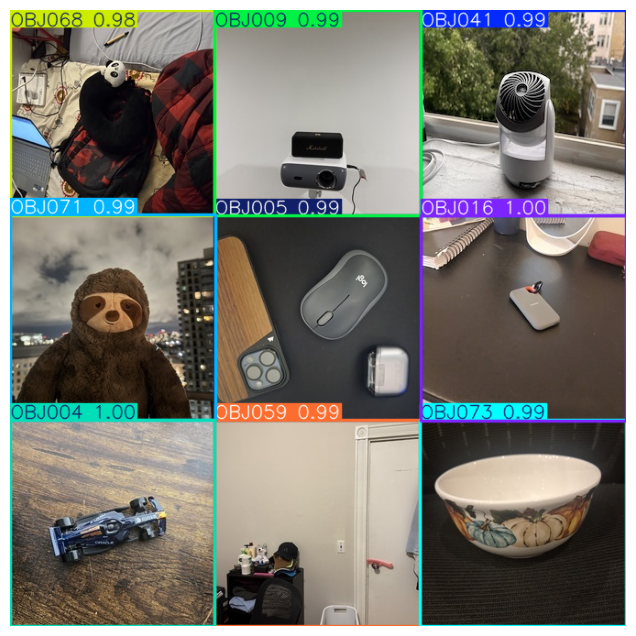

In [18]:
def detect(path, conf=0.4):
    r = best.predict(str(path), imgsz=672, conf=conf, agnostic_nms=True, verbose=False)[0]
    dets = []
    for b in r.boxes:
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
        dets.append((best.names[int(b.cls)], round(float(b.conf), 2), (x1, y1, x2, y2)))
        print(f"{best.names[int(b.cls)]:>8}  {float(b.conf):.2f}  ({x1}, {y1}, {x2}, {y2})")
    plt.figure(figsize=(8, 8)); plt.imshow(r.plot()[:, :, ::-1]); plt.axis("off"); plt.show()
    return dets

for s in ["sample_1x1.jpg", "sample_2x2.jpg", "sample_3x3.jpg"]:
    print(s)
    detect(OUT / "examples" / s)

### Save results to Drive

In [19]:
dest = Path("/content/drive/MyDrive/IE7615_M2_results")
shutil.copytree("/content/runs", dest / "runs", dirs_exist_ok=True)
shutil.copytree(OUT / "examples", dest / "examples", dirs_exist_ok=True)
shutil.copy(OUT / "data.yaml", dest)
shutil.copy(run_dir / "weights" / "best.pt", dest / "best.pt")   # easy-to-find copy for the demo
print("saved to", dest)

saved to /content/drive/MyDrive/IE7615_M2_results
